# SS3 Part B: Applying the final method to the STADIOchoice client data

**Module:** CAP182 Capstone Project  |  **Client:** STADIOchoice (streaming service STADIOstream)
**Business problem:** predict which streaming subscribers will cancel (churn) *before* they cancel, so that retention offers go only to subscribers who are really at risk, instead of to everyone who clicks "cancel".

**The five required components of this notebook**

| # | Component | Where |
|---|---|---|
| 1 | Dataset loading | section 1 |
| 2 | Dataset preprocessing (including the train / validation / test split) | section 2 |
| 3 | Model training | section 3 |
| 4 | Model validation | section 4 |
| 5 | Results visualisation | section 5 |

**How this follows from SS2.** In SS2 two models were built and compared on a public dataset: *Model 1, Logistic Regression* and *Model 2, Random Forest*. SS2 chose Model 1. Here the **same two models, with the same hyper-parameters and the same random seed**, are applied to the real data supplied by the client. The final model is chosen by a rule that is written down *before* the validation results are looked at (section 4.4).

**Three things to know before reading**

1. **The client data contains leakage traps.** The client's own README warns that some columns are measured *after* a subscriber has already left, so they reveal the answer. A model that used them would look perfect and be useless. Section 2.5 shows the evidence and section 2.6 lists what was removed.
2. **Because of this, the results are modest, and that is the honest result.** A leakage-free model for this data has only account and billing information to work with.
3. **Validation is done carefully:** a stratified 60 / 20 / 20 split, all fitting on the training set only, the test set used once, and bootstrap confidence intervals on every metric.

**How to run it.** Put the three client CSV files in `datasets/client_data/` (or set the environment variable `STADIO_DATA_DIR`), then run all cells from top to bottom. Results are written to `experimental_results/` and `models/`.

## 1. Dataset loading

This section loads the client's data exactly as it was supplied and describes it: how many instances there are, what the classes are and how imbalanced they are.

In [1]:
import os, sys, json, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

# ---- settings that are fixed for the whole notebook -------------------------------
SEED = 42                               # same seed as SS2
INDEX_DATE = pd.Timestamp("2025-09-01") # start of the observation window (see 2.3)
CONTACT_FRACTION = 0.20                 # retention team can contact the top 20% riskiest subscribers
N_BOOT = 1000                           # bootstrap resamples for confidence intervals

RESULTS_DIR = Path("experimental_results")
MODELS_DIR = Path("models")
FIG_DIR = RESULTS_DIR                   # figures are saved next to the other results
for folder in (RESULTS_DIR, MODELS_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

FILES = {"billing": "table1_subscription_billing.csv",
         "viewing": "table2_streaming_viewing_behaviour.csv",
         "cancellation": "table3_cancellation_retention.csv"}

def find_data_dir():
    """Find the folder that holds the three client CSV files."""
    candidates = [os.environ.get("STADIO_DATA_DIR", ""), "datasets/client_data", "datasets/stadiochoice",
                  "datasets", "client_data", "data", "."]
    for d in candidates:
        if d and all((Path(d) / f).exists() for f in FILES.values()):
            return Path(d)
    for hit in Path(".").rglob(FILES["billing"]):
        if all((hit.parent / f).exists() for f in FILES.values()):
            return hit.parent
    raise FileNotFoundError("Could not find the three client CSV files. Put them in datasets/client_data/ "
                            "or set the STADIO_DATA_DIR environment variable.")

DATA_DIR = find_data_dir()
print("Loading client data from:", DATA_DIR)
print(f"python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Loading client data from: datasets/client_data
python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0


In [2]:
# Every column is first read as text so that data types are set deliberately (and checked) in section 2,
# instead of being guessed by the reader.
raw = {key: pd.read_csv(DATA_DIR / fname, dtype=str) for key, fname in FILES.items()}

summary = pd.DataFrame({
    "file": list(FILES.values()),
    "rows": [len(raw[k]) for k in FILES],
    "columns": [raw[k].shape[1] for k in FILES],
    "unique subscriber_id": [raw[k]["subscriber_id"].nunique() for k in FILES],
}, index=list(FILES))
display(summary)

for k in FILES:
    print(f"\n{k} table columns: {list(raw[k].columns)}")
    display(raw[k].head(3))


billing table columns: ['subscriber_id', 'plan_type', 'monthly_price', 'subscription_start_date', 'tenure_months', 'payment_status', 'payment_failures_last_6_months', 'upgrade_downgrade_history', 'free_trial_flag']

viewing table columns: ['subscriber_id', 'titles_watched_last_30_days', 'total_watch_time_last_30_days_minutes', 'days_since_last_login', 'search_count_last_30_days', 'zero_result_search_flag', 'device_type']

cancellation table columns: ['subscriber_id', 'churned', 'cancellation_date', 'cancellation_reason', 'retention_offer_made', 'retention_offer_accepted']


,file,rows,columns,unique subscriber_id
billing,table1_subscription_billing.csv,28188,9,28104
viewing,table2_streaming_viewing_behaviour.csv,28104,7,28104
cancellation,table3_cancellation_retention.csv,28104,6,28104


,subscriber_id,plan_type,monthly_price,subscription_start_date,tenure_months,payment_status,payment_failures_last_6_months,upgrade_downgrade_history,free_trial_flag
0,SUB00100000,Premium,199.0,2023-02-03,42,Success,0,No change,FALSE
1,SUB00100001,Premium 4K,279.0,2026-07-07,1,Success,0,Upgraded,FALSE
2,SUB00100002,Basic,99.0,2022-05-21,51,Success,1,Upgraded,FALSE


,subscriber_id,titles_watched_last_30_days,total_watch_time_last_30_days_minutes,days_since_last_login,search_count_last_30_days,zero_result_search_flag,device_type
0,SUB00100000,15,1106.3,3,11,TRUE,Mobile
1,SUB00100001,2,89.5,3,10,FALSE,Mobile
2,SUB00100002,5,19.5,2,0,FALSE,Smart TV


,subscriber_id,churned,cancellation_date,cancellation_reason,retention_offer_made,retention_offer_accepted
0,SUB00100000,FALSE,NaN,NaN,FALSE,FALSE
1,SUB00100001,FALSE,NaN,NaN,FALSE,FALSE
2,SUB00100002,FALSE,NaN,NaN,FALSE,FALSE


Raw values of the target column 'churned':
churned
FALSE    23513
TRUE      4591

instances = 28,104 | stayed = 23,513 | churned = 4,591
churn rate = 16.34% | imbalance = 5.12 : 1 | accuracy of 'always predict stay' = 83.66%


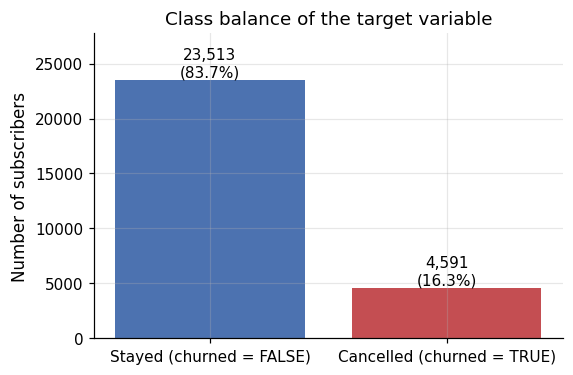

In [3]:
# Class distribution of the target ("churned", in the cancellation table)
print("Raw values of the target column 'churned':")
print(raw["cancellation"]["churned"].value_counts(dropna=False).to_string())

n_instances = int(raw["cancellation"]["subscriber_id"].nunique())
n_churn = int((raw["cancellation"]["churned"].str.strip().str.upper() == "TRUE").sum())
n_stay = n_instances - n_churn
prevalence = n_churn / n_instances
imbalance_ratio = n_stay / n_churn
majority_baseline_accuracy = n_stay / n_instances
print(f"\ninstances = {n_instances:,} | stayed = {n_stay:,} | churned = {n_churn:,}")
print(f"churn rate = {prevalence:.2%} | imbalance = {imbalance_ratio:.2f} : 1 | accuracy of 'always predict stay' = {majority_baseline_accuracy:.2%}")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
bars = ax.bar(["Stayed (churned = FALSE)", "Cancelled (churned = TRUE)"], [n_stay, n_churn], color=["#4c72b0", "#c44e52"])
for b, v in zip(bars, [n_stay, n_churn]):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / n_instances:.1%})", ha="center", va="bottom")
ax.set_ylim(0, n_stay * 1.18)
ax.set_ylabel("Number of subscribers")
ax.set_title("Class balance of the target variable")
plt.show()

### 1.1 What was loaded

**Source.** STADIOchoice supplied three CSV tables and a README. All three describe the same subscribers and are linked by `subscriber_id`. The pack for this project contains only these three tables, and all three are relevant:

| Table | What it holds | Rows | Columns |
|---|---|---|---|
| `table1_subscription_billing.csv` | plan, price, start date, tenure, payment history | 28,188 | 9 |
| `table2_streaming_viewing_behaviour.csv` | watching, login and search behaviour, device | 28,104 | 7 |
| `table3_cancellation_retention.csv` | whether the subscriber cancelled (**the target**), cancellation details, retention offers | 28,104 | 6 |

**Number of instances.** The billing table has 28,188 rows, of which 84 are exact duplicates (removed in section 2). The other two tables have 28,104 rows each. After the duplicates are removed and the tables are joined, there is **one row per subscriber, so 28,104 instances**.

**Classes.** The target is `churned` (table 3):

* `FALSE`: the subscriber stayed: **23,513** subscribers (83.66%)
* `TRUE`: the subscriber cancelled during the observation window: **4,591** subscribers (16.34%)

**Imbalance proportion.** **5.12 : 1** (stayed : cancelled). This matters for every later decision:

* *Accuracy is misleading.* A model that always says "will stay" would be right 83.7% of the time while catching no churner at all. So the notebook judges models with ranking metrics (ROC-AUC, PR-AUC) and with precision and recall on the churn class.
* The split is **stratified** so every subset keeps the same 16.3% churn rate.
* Both models use `class_weight="balanced"` (as in SS2) so mistakes on the rarer class are not ignored.

**Why the CSV format is appropriate, and how it is used.** The client supplies one text table per kind of information, linked by a key (`subscriber_id`), and the data is small (about 84 thousand rows in total, roughly 4 MB). A plain CSV is human-readable and keeps the data exactly as supplied. A binary format such as Parquet would only pay off for much larger data. Each table has exactly one row per subscriber, so the tables are joined one-to-one on `subscriber_id` (checked in section 2). Reading every column as text first means that no type is guessed silently: each type is set and validated explicitly in the next section.